In [2]:
# 1. Dataset Acquisition: Download Heart Failure Clinical Records Dataset
# 2. Load Dataset: Read dataset as pandas DataFrame, display first 5 rows.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)


heart_failure_df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

print("Shape:", heart_failure_df.shape)
heart_failure_df.head()

Shape: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [3]:
# 3. Summarize Dataset: Report number of rows, columns, data types, missing values.
print(f"Number of rows: {heart_failure_df.shape[0]}")
print(f"Number of columns: {heart_failure_df.shape[1]}")


print("Data types:\n")
print(heart_failure_df.dtypes)

missing_counts = heart_failure_df.isna().sum()
missing_pct = (missing_counts / len(heart_failure_df)) * 100

missing_report = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percent": missing_pct.round(2)
})

print("Missing values report:\n")
print(missing_report)

Number of rows: 299
Number of columns: 13
Data types:

age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object
Missing values report:

                          missing_count  missing_percent
age                                   0              0.0
anaemia                               0              0.0
creatinine_phosphokinase              0              0.0
diabetes                              0              0.0
ejection_fraction                     0              0.0
high_blood_pressure                   0              0.0
platelets                             0 

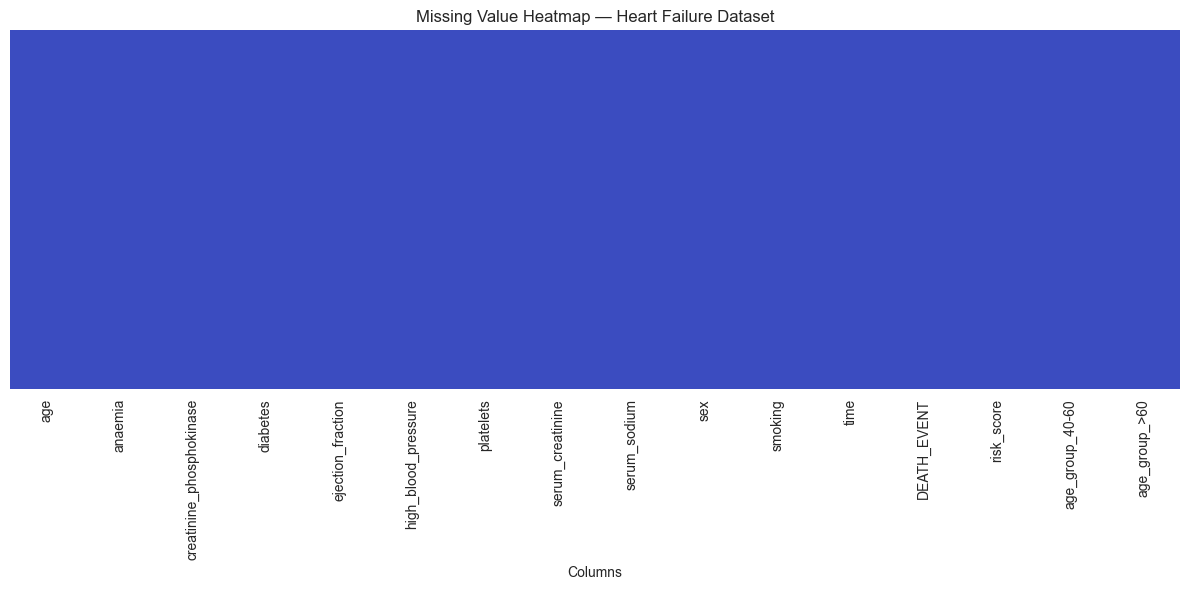

In [21]:
# 4. Visualize Missing Values: Create heatmap using seaborn to show missing values.
plt.figure(figsize=(12, 6))
sns.heatmap(heart_failure_df.isna(), cbar=False, cmap="coolwarm", yticklabels=False)
plt.title("Missing Value Heatmap — Heart Failure Dataset")
plt.xlabel("Columns")
plt.tight_layout()
plt.show()

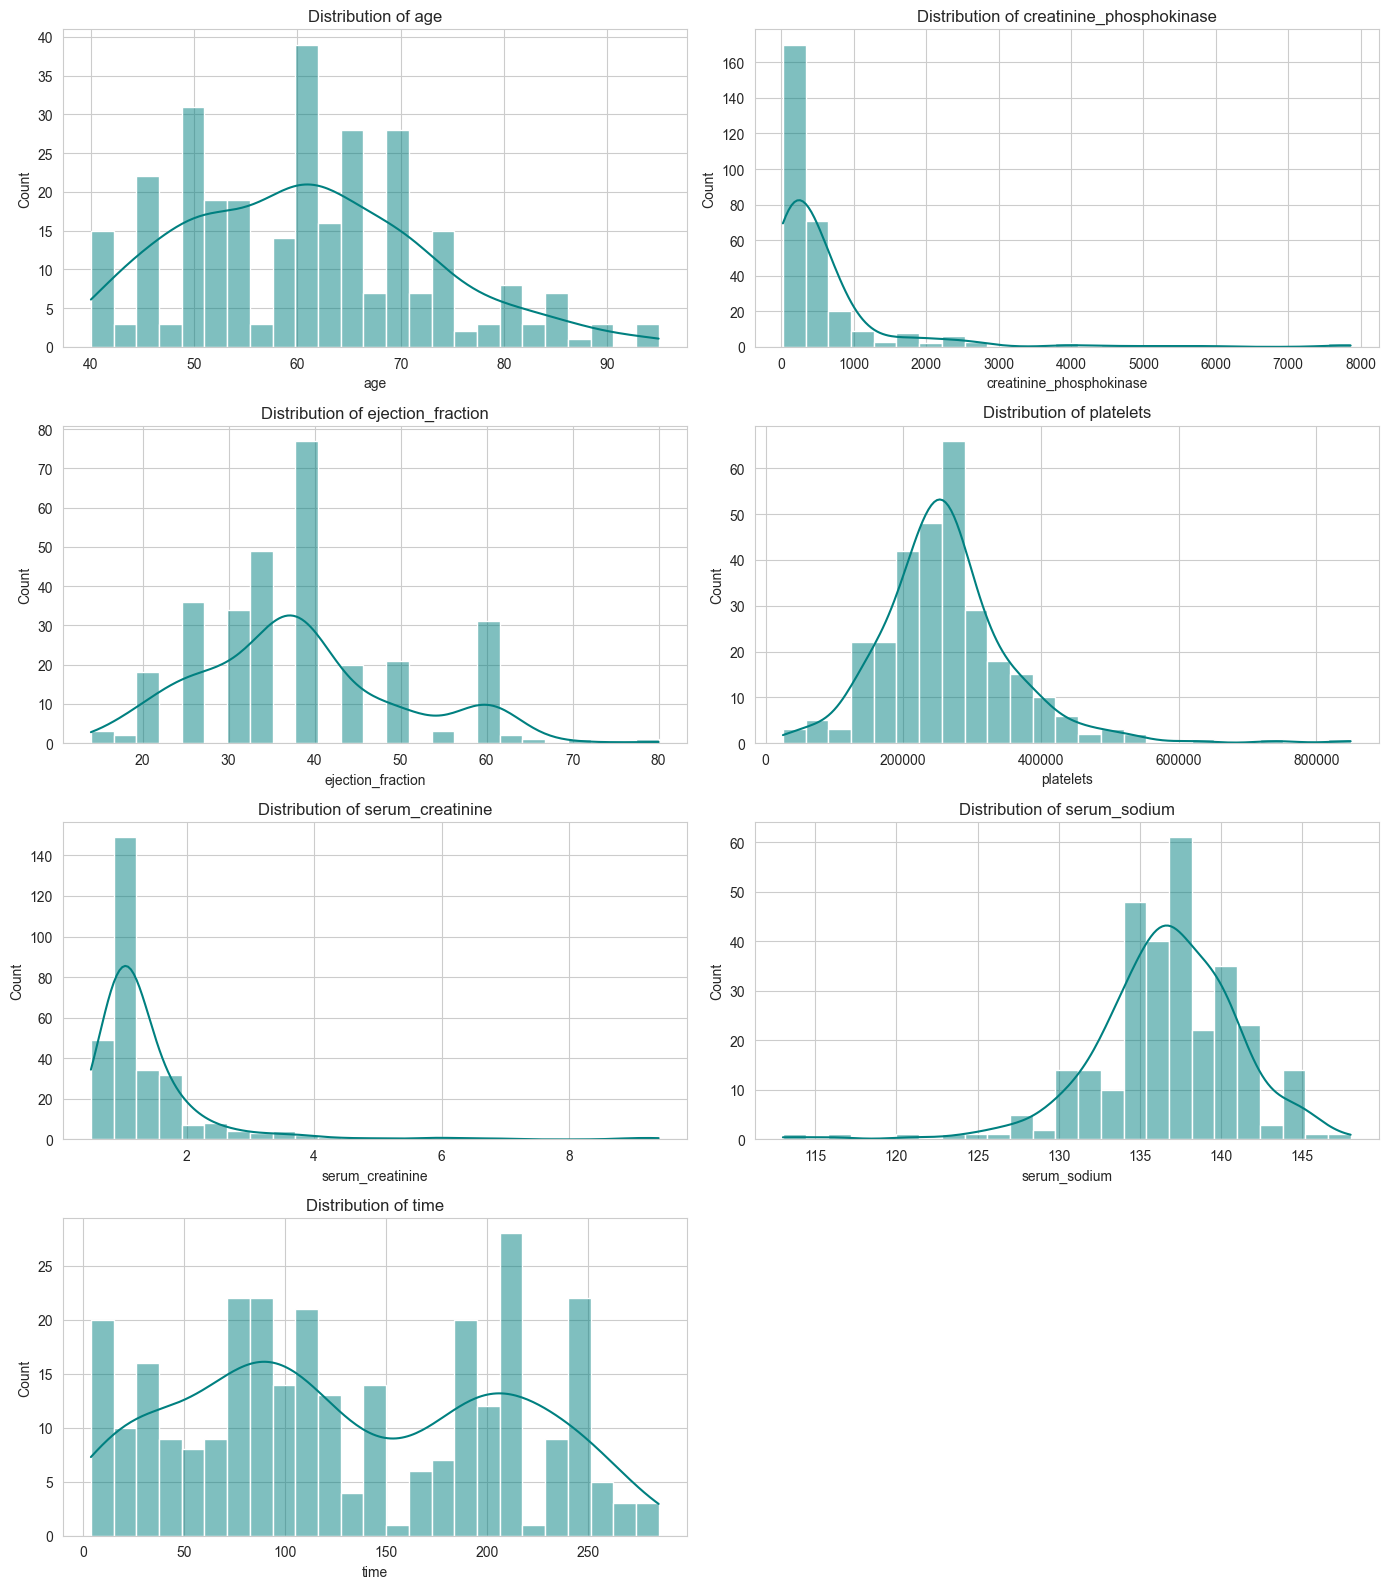

In [5]:
# 5. Plot Distributions: Generate histograms or boxplots for numerical features (e.g., age, ejection_fraction).
numerical_cols = ["age", "creatinine_phosphokinase", "ejection_fraction",
                   "platelets", "serum_creatinine", "serum_sodium", "time"]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for ax, col in zip(axes, numerical_cols):
    sns.histplot(heart_failure_df[col], kde=True, ax=ax, color="teal", bins=25)
    ax.set_title(f"Distribution of {col}")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [6]:
# Impute Missing Values:
# • Numerical features: Use mean or median (e.g., serum_creatinine).
# • Categorical features: Use mode or "Unknown" (e.g., smoking).
# Numerical features: impute with median (more robust to outliers than mean)
numerical_cols = ["age", "creatinine_phosphokinase", "ejection_fraction",
                   "platelets", "serum_creatinine", "serum_sodium", "time"]
categorical_cols = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking"]

for col in numerical_cols:
    if heart_failure_df[col].isna().any():
        median_val = heart_failure_df[col].median()
        heart_failure_df[col] = heart_failure_df[col].fillna(median_val)
        print(f"Filled {col} with median: {median_val}")

# Categorical features: impute with mode
for col in categorical_cols:
    if heart_failure_df[col].isna().any():
        mode_val = heart_failure_df[col].mode(dropna=True)[0]
        heart_failure_df[col] = heart_failure_df[col].fillna(mode_val)
        print(f"Filled {col} with mode: {mode_val}")

print("Missing values after imputation:", heart_failure_df.isna().sum().sum())

Missing values after imputation: 0


In [7]:
# 7. check outliers
# Using the IQR (Interquartile Range) method — a standard, defensible approach
# for outlier removal on numerical clinical features.
outlier_cols = ["creatinine_phosphokinase", "platelets", "serum_creatinine", "serum_sodium"]

print("Rows before outlier removal:", heart_failure_df.shape[0])

for col in outlier_cols:
    Q1 = heart_failure_df[col].quantile(0.25)
    Q3 = heart_failure_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    before_count = heart_failure_df.shape[0]
    heart_failure_df = heart_failure_df[
        (heart_failure_df[col] >= lower_bound) & (heart_failure_df[col] <= upper_bound)
    ]
    removed = before_count - heart_failure_df.shape[0]
    print(f"{col}: removed {removed} outlier rows (bounds: {lower_bound:.2f} to {upper_bound:.2f})")

print("\nRows after outlier removal:", heart_failure_df.shape[0])

Rows before outlier removal: 299
creatinine_phosphokinase: removed 29 outlier rows (bounds: -581.75 to 1280.25)
platelets: removed 18 outlier rows (bounds: 72125.00 to 441125.00)
serum_creatinine: removed 24 outlier rows (bounds: 0.15 to 2.15)
serum_sodium: removed 3 outlier rows (bounds: 125.00 to 149.00)

Rows after outlier removal: 225


In [8]:
# 8. Correct Inconsistencies: Check and fix invalid entries (e.g., negative age).

print("Age range:", heart_failure_df["age"].min(), "-", heart_failure_df["age"].max())
print("Ejection fraction range:", heart_failure_df["ejection_fraction"].min(), "-", heart_failure_df["ejection_fraction"].max())
print("Platelets range:", heart_failure_df["platelets"].min(), "-", heart_failure_df["platelets"].max())
print("Serum sodium range:", heart_failure_df["serum_sodium"].min(), "-", heart_failure_df["serum_sodium"].max())
print("Serum creatinine range:", heart_failure_df["serum_creatinine"].min(), "-", heart_failure_df["serum_creatinine"].max())

# Binary/categorical columns should only contain 0 or 1
binary_cols = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking", "DEATH_EVENT"]
for col in binary_cols:
    unique_vals = heart_failure_df[col].unique()
    print(f"{col} unique values: {sorted(unique_vals)}")

Age range: 40.0 - 95.0
Ejection fraction range: 14 - 80
Platelets range: 122000.0 - 427000.0
Serum sodium range: 125 - 148
Serum creatinine range: 0.6 - 2.1
anaemia unique values: [np.int64(0), np.int64(1)]
diabetes unique values: [np.int64(0), np.int64(1)]
high_blood_pressure unique values: [np.int64(0), np.int64(1)]
sex unique values: [np.int64(0), np.int64(1)]
smoking unique values: [np.int64(0), np.int64(1)]
DEATH_EVENT unique values: [np.int64(0), np.int64(1)]


In [9]:
# Fix invalid entries where found
n_before = heart_failure_df.shape[0]

# Age cannot be negative or zero
heart_failure_df = heart_failure_df[heart_failure_df["age"] > 0]

# Ejection fraction is a percentage — must be between 0 and 100
heart_failure_df = heart_failure_df[
    (heart_failure_df["ejection_fraction"] > 0) & (heart_failure_df["ejection_fraction"] <= 100)
]

# Platelets, serum_creatinine, serum_sodium cannot be negative or zero
heart_failure_df = heart_failure_df[heart_failure_df["platelets"] > 0]
heart_failure_df = heart_failure_df[heart_failure_df["serum_creatinine"] > 0]
heart_failure_df = heart_failure_df[heart_failure_df["serum_sodium"] > 0]

n_after = heart_failure_df.shape[0]
print(f"Rows removed due to invalid entries: {n_before - n_after}")
print(f"Rows remaining: {n_after}")

Rows removed due to invalid entries: 0
Rows remaining: 225


In [10]:
# 9. Feature Engineering:
# Create age_group feature (bins: <40, 40–60, >60).

def assign_age_group(age):
    if age < 40:
        return "<40"
    elif age <= 60:
        return "40-60"
    else:
        return ">60"

heart_failure_df["age_group"] = heart_failure_df["age"].apply(assign_age_group)


heart_failure_df[["age", "age_group"]].head()

,age,age_group
0,75.0,>60
2,65.0,>60
3,50.0,40-60
5,90.0,>60
6,75.0,>60


In [11]:
# Create risk_score feature (e.g., normalized product of ejection_fraction, serum_creatinine).
from sklearn.preprocessing import MinMaxScaler

# Normalize ejection_fraction and serum_creatinine to 0-1 first, so their scales
# don't dominate the product (ejection_fraction ~14-80, serum_creatinine ~0.6-2.1)
scaler_temp = MinMaxScaler()
normalized_vals = scaler_temp.fit_transform(
    heart_failure_df[["ejection_fraction", "serum_creatinine"]]
)

ejection_norm = normalized_vals[:, 0]
creatinine_norm = normalized_vals[:, 1]

# Lower ejection fraction + higher serum creatinine = higher risk,
# so invert ejection_fraction before multiplying
heart_failure_df["risk_score"] = (1 - ejection_norm) * creatinine_norm

print(heart_failure_df[["ejection_fraction", "serum_creatinine", "risk_score"]].head(10))
print("\nrisk_score range:", heart_failure_df["risk_score"].min(), "-", heart_failure_df["risk_score"].max())

    ejection_fraction  serum_creatinine  risk_score
0                  20               1.9    0.787879
2                  20               1.3    0.424242
3                  20               1.9    0.787879
5                  40               2.1    0.606061
6                  15               1.2    0.393939
8                  65               1.5    0.136364
11                 25               0.9    0.166667
12                 30               1.1    0.252525
13                 38               1.1    0.212121
14                 30               1.0    0.202020

risk_score range: 0.0 - 0.8333333333333334


In [12]:
# 10. Encode Categorical Variables: Apply one-hot or label encoding to categorical features (e.g., sex, smoking).

# One-hot encode age_group (creates separate binary columns per category)
heart_failure_df = pd.get_dummies(heart_failure_df, columns=["age_group"], prefix="age_group")

print(heart_failure_df.filter(like="age_group").head())
print("\nColumns after encoding:", heart_failure_df.columns.tolist())

   age_group_40-60  age_group_>60
0            False           True
2            False           True
3             True          False
5            False           True
6            False           True

Columns after encoding: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time', 'DEATH_EVENT', 'risk_score', 'age_group_40-60', 'age_group_>60']


In [13]:
# 11. Normalize Features: Scale numerical features (e.g., age, platelets) to 0–1 using MinMaxScaler.
from sklearn.preprocessing import MinMaxScaler

# Save a copy of the original values before scaling, for later "before vs after" comparison
numerical_cols = ["age", "creatinine_phosphokinase", "ejection_fraction",
                   "platelets", "serum_creatinine", "serum_sodium", "time"]

heart_failure_df_before_scaling = heart_failure_df[numerical_cols].copy()

scaler = MinMaxScaler()
heart_failure_df[numerical_cols] = scaler.fit_transform(heart_failure_df[numerical_cols])

print(heart_failure_df[numerical_cols].head())
print("\nConfirm 0-1 range:")
print(heart_failure_df[numerical_cols].describe().loc[["min", "max"]])

        age  creatinine_phosphokinase  ejection_fraction  platelets  \
0  0.636364                  0.470990           0.090909   0.468852   
2  0.454545                  0.098976           0.090909   0.131148   
3  0.181818                  0.069113           0.090909   0.288525   
5  0.909091                  0.014505           0.393939   0.268852   
6  0.636364                  0.184300           0.015152   0.016393   

   serum_creatinine  serum_sodium      time  
0          0.866667      0.217391  0.000000  
2          0.466667      0.173913  0.010676  
3          0.866667      0.521739  0.010676  
5          1.000000      0.304348  0.014235  
6          0.400000      0.521739  0.021352  

Confirm 0-1 range:
     age  creatinine_phosphokinase  ejection_fraction  platelets  \
min  0.0                       0.0                0.0        0.0   
max  1.0                       1.0                1.0        1.0   

     serum_creatinine  serum_sodium  time  
min               0.0       

In [14]:
#  12. Compute Summary Statistics: Calculate mean, median, standard deviation before and after cleaning.


original_df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

comparison_cols = ["age", "creatinine_phosphokinase", "ejection_fraction",
                    "platelets", "serum_creatinine", "serum_sodium", "time"]

before_stats = original_df[comparison_cols].agg(["mean", "median", "std"]).T
after_stats = heart_failure_df_before_scaling[comparison_cols].agg(["mean", "median", "std"]).T

comparison_df = before_stats.join(after_stats, lsuffix="_before", rsuffix="_after")
comparison_df = comparison_df[["mean_before", "mean_after", "median_before", "median_after", "std_before", "std_after"]]

print("Summary statistics: before vs after cleaning\n")
print(comparison_df.round(3))

Summary statistics: before vs after cleaning

                          mean_before  mean_after  median_before  \
age                            60.834      60.739           60.0   
creatinine_phosphokinase      581.839     338.031          250.0   
ejection_fraction              38.084      38.364           38.0   
platelets                  263358.029  255898.492       262000.0   
serum_creatinine                1.394       1.129            1.1   
serum_sodium                  136.625     137.044          137.0   
time                          130.261     132.342          115.0   

                          median_after  std_before  std_after  
age                               60.0      11.895     11.966  
creatinine_phosphokinase         212.0     970.288    279.375  
ejection_fraction                 38.0      11.835     12.013  
platelets                     263000.0   97804.237  67005.547  
serum_creatinine                   1.1       1.035      0.327  
serum_sodium             

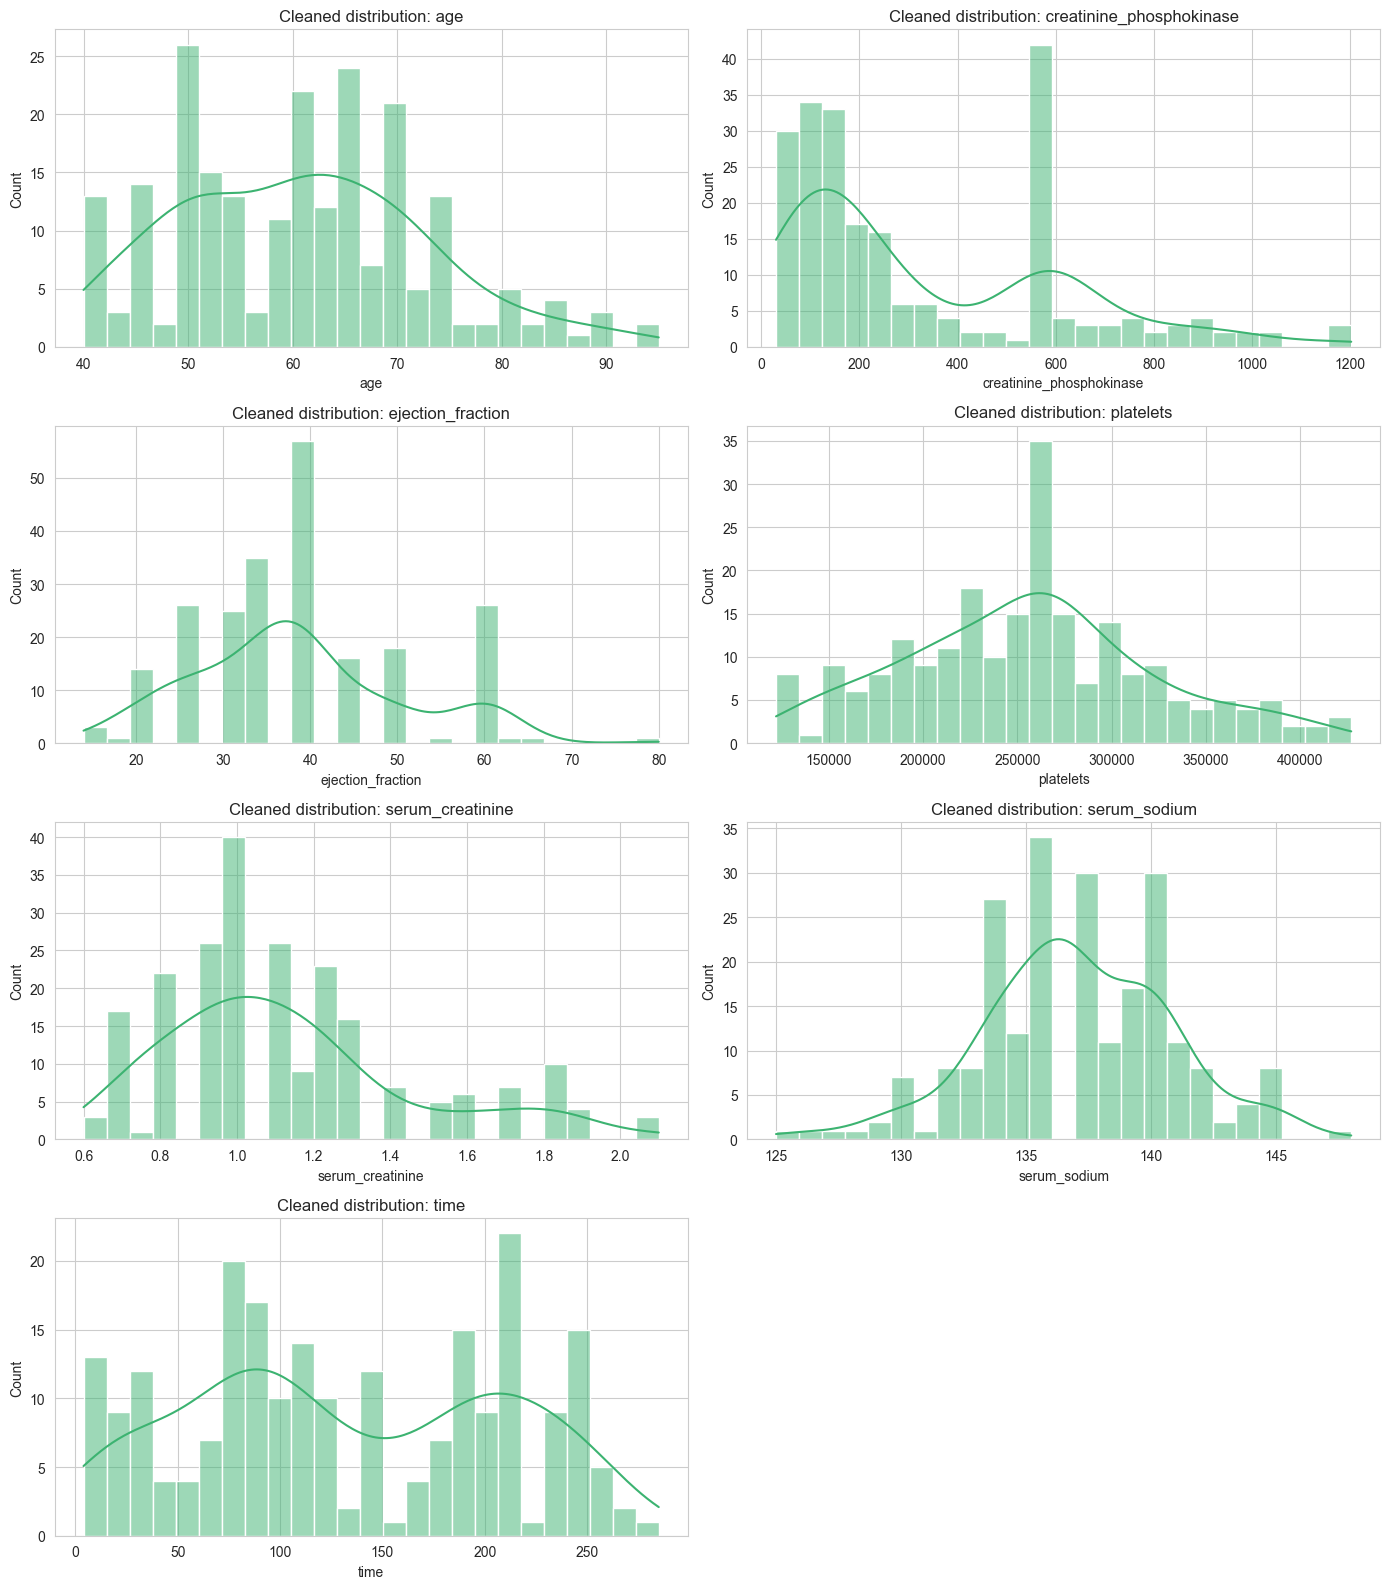

In [15]:
# 13. Validate Cleaning: Plot histograms or boxplots for cleaned numerical features.

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for ax, col in zip(axes, numerical_cols):
    sns.histplot(heart_failure_df_before_scaling[col], kde=True, ax=ax, color="mediumseagreen", bins=25)
    ax.set_title(f"Cleaned distribution: {col}")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

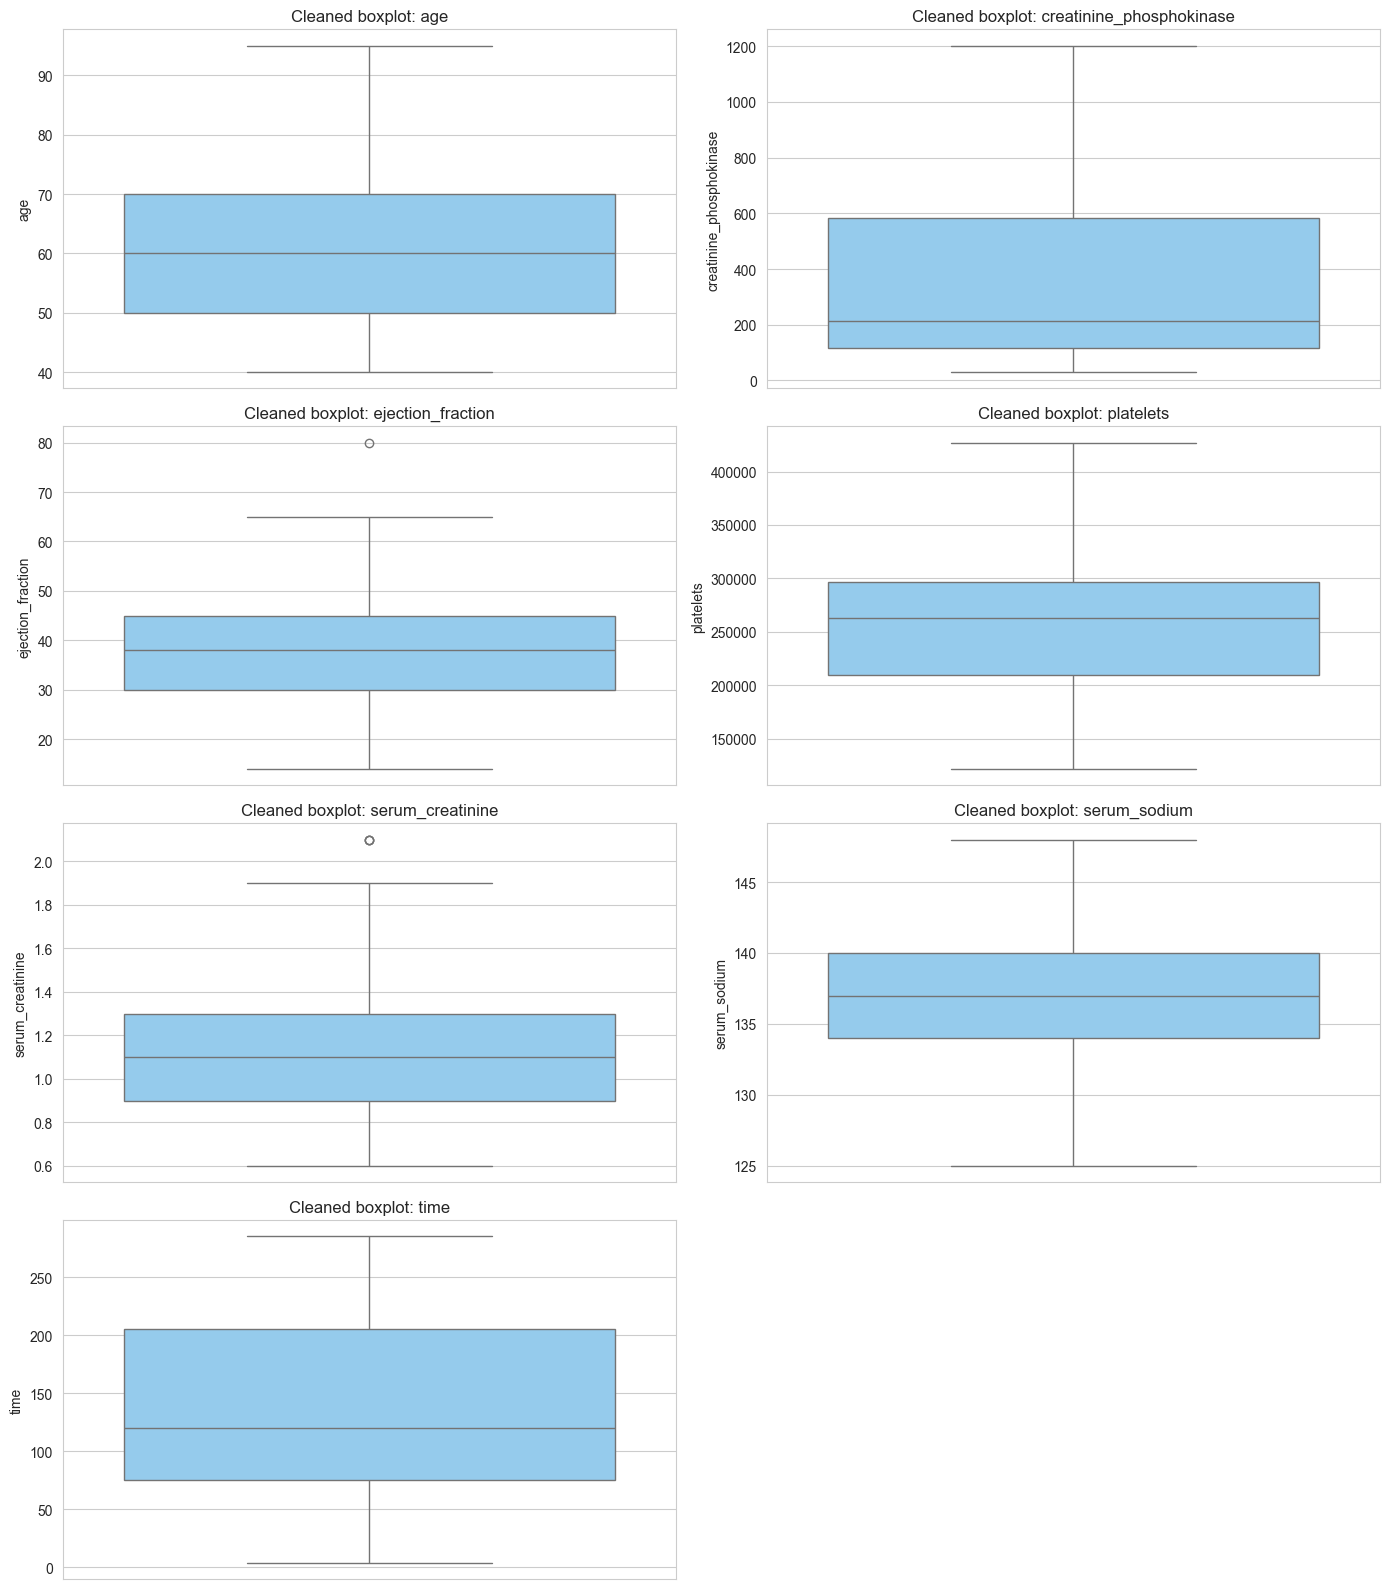

In [16]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for ax, col in zip(axes, numerical_cols):
    sns.boxplot(y=heart_failure_df_before_scaling[col], ax=ax, color="lightskyblue")
    ax.set_title(f"Cleaned boxplot: {col}")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [17]:
# 14. Check Missing Values: Confirm no missing values remain or justify any remaining.
final_missing = heart_failure_df.isna().sum()
final_missing = final_missing[final_missing > 0]

if final_missing.empty:
    print("No missing values remain in the cleaned dataset.")
else:
    print("Missing values still present:\n", final_missing)

print("\nFinal cleaned dataset shape:", heart_failure_df.shape)

No missing values remain in the cleaned dataset.

Final cleaned dataset shape: (225, 16)
